In [ ]:
pip install keras_tuner

In [ ]:
pip install "numpy<2"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import keras_tuner as kt
df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")


2026-05-04 00:25:02.364456: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 00:25:03.215299: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 00:25:03.418288: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-04 00:25:03.418330: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-04 00:25:03.418422: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [2]:
df

,timestamp,symbol,open,high,low,close,volume,sma_10,sma_50,ema_20,...,sum_of_scores,avg_of_scores,normalized_avg,max_of_scores,min_of_scores,normalized_min,normalized_max,avg_score_of_normalized_min,avg_score_of_normalized_max,avg_score_of_normalized_avg
0,2023-01-03 09:00:00,TSLA,120.02,121.23,115.94,118.52,1306706,118.5200,118.5200,118.520000,...,"[-7, 2, 7, 1, -2, 5, 2, 0, 1, 5]","[-3.5, 1.0, 3.5, 0.5, -1.0, 2.5, 1.0, 0.0, 0.5...","[-0.7, 0.2, 0.7, 0.1, -0.2, 0.5, 0.2, 0.0, 0.1...","[-3, 1, 5, 4, 0, 5, 3, 1, 1, 3]","[-4, 1, 2, -3, -2, 0, -1, -1, 0, 2]","[-0.8, 0.2, 0.4, -0.6, -0.4, 0.0, -0.2, -0.2, ...","[-0.6, 0.2, 1.0, 0.8, 0.0, 1.0, 0.6, 0.2, 0.2,...",-0.12,0.40,0.140000
1,2023-01-03 10:00:00,TSLA,118.53,120.50,118.20,120.38,568635,119.4500,119.4500,118.697143,...,"[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2.0, 5.0, 0.0, 3.0, -1.0, 4.0, 0.0, -2.0, -2....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....",0.26,0.26,0.260000
2,2023-01-03 11:00:00,TSLA,120.28,120.50,117.95,118.61,547403,119.1700,119.1700,118.688844,...,"[-18, 14, 10, 10, 2, 11, -2, 15, -7, -7]","[-3.0, 2.3333333333333335, 1.6666666666666667,...","[-0.6, 0.4666666666666667, 0.33333333333333337...","[-2, 5, 4, 5, 1, 5, 3, 6, 1, 2]","[-5, 0, 0, -2, -1, -1, -4, 0, -5, -5]","[-1.0, 0.0, 0.0, -0.4, -0.2, -0.2, -0.8, 0.0, ...","[-0.4, 1.0, 0.8, 1.0, 0.2, 1.0, 0.6, 1.2, 0.2,...",-0.46,0.60,0.093333
3,2023-01-03 12:00:00,TSLA,118.63,118.99,116.61,118.28,1529445,118.9475,118.9475,118.649906,...,"[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4.0, 0.0, 3.0, -1.0, -5.0, 0.0, 0.0, -2.0, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...",-0.24,-0.24,-0.240000
4,2023-01-03 13:00:00,TSLA,118.32,121.90,116.61,118.93,2886437,118.9440,118.9440,118.676582,...,"[-20, 2, 19, 16, 6, 16, 4, 5, -2, 9]","[-2.5, 0.25, 2.375, 2.0, 0.75, 2.0, 0.5, 0.625...","[-0.5, 0.05, 0.475, 0.4, 0.15, 0.4, 0.1, 0.125...","[0, 2, 5, 4, 5, 5, 3, 3, 2, 5]","[-5, -4, 0, -4, -5, -2, -2, -3, -5, -1]","[-1.0, -0.8, 0.0, -0.8, -1.0, -0.4, -0.4, -0.6...","[0.0, 0.4, 1.0, 0.8, 1.0, 1.0, 0.6, 0.6, 0.4, ...",-0.62,0.68,0.137500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,2023-12-08 13:00:00,TSLA,242.19,243.37,239.75,240.40,1406899,242.3970,241.1094,241.760952,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1033,2023-12-08 14:00:00,TSLA,240.46,243.65,239.27,242.40,15237079,242.3730,241.2916,241.821814,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1034,2023-12-08 15:00:00,TSLA,242.40,245.23,242.40,245.19,22432349,242.6320,241.5218,242.142593,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1035,2023-12-08 16:00:00,TSLA,245.19,245.27,241.67,241.97,15853691,242.5470,241.5982,242.126156,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0,

Trial 5 Complete [00h 00m 13s]
val_loss: 0.00248256279155612

Best val_loss So Far: 0.0011437705252319574
Total elapsed time: 00h 01m 08s
Epoch 1/1000
3/3 [==============================] - 4s 383ms/step - loss: 0.1295 - val_loss: 0.1101
Epoch 2/1000
3/3 [==============================] - 0s 56ms/step - loss: 0.0390 - val_loss: 0.0171
Epoch 3/1000
3/3 [==============================] - 0s 54ms/step - loss: 0.0150 - val_loss: 0.0300
Epoch 4/1000
3/3 [==============================] - 0s 54ms/step - loss: 0.0146 - val_loss: 0.0042
Epoch 5/1000
3/3 [==============================] - 0s 54ms/step - loss: 0.0098 - val_loss: 0.0019
Epoch 6/1000
3/3 [==============================] - 0s 50ms/step - loss: 0.0063 - val_loss: 0.0055
Epoch 7/1000
3/3 [==============================] - 0s 52ms/step - loss: 0.0044 - val_loss: 0.0099
Epoch 8/1000
3/3 [==============================] - 0s 53ms/step - loss: 0.0044 - val_loss: 0.0037
Epoch 9/1000
3/3 [==============================] - 0s 52ms/step - lo

3/3 [==============================] - 0s 55ms/step - loss: 0.0012 - val_loss: 9.8450e-04
Epoch 82/1000
3/3 [==============================] - 0s 51ms/step - loss: 0.0011 - val_loss: 0.0013
Epoch 83/1000
3/3 [==============================] - 0s 51ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 84/1000
3/3 [==============================] - 0s 52ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 85/1000
3/3 [==============================] - 0s 53ms/step - loss: 0.0011 - val_loss: 9.6716e-04
Epoch 86/1000
3/3 [==============================] - 0s 52ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 87/1000
3/3 [==============================] - 0s 51ms/step - loss: 0.0011 - val_loss: 9.5635e-04
Epoch 88/1000
3/3 [==============================] - 0s 52ms/step - loss: 0.0010 - val_loss: 0.0011
Epoch 89/1000
3/3 [==============================] - 0s 51ms/step - loss: 0.0010 - val_loss: 9.9039e-04
Epoch 90/1000
3/3 [==============================] - 0s 52ms/step - loss: 0.0010 - val_loss: 0.001

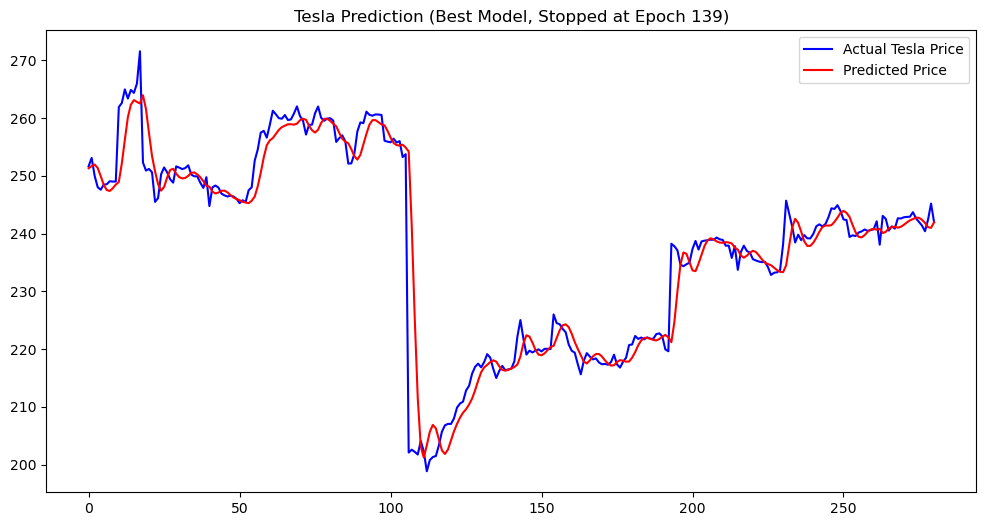

Final RMSE: 5.19
Raw Prediction Sample: [0.8206309  0.8226425  0.82421035 0.82087904 0.81316996]


NameError: name 'trainPredict' is not defined

In [3]:


# --- 1. Data Preparation (Split then Normalize) ---
#df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
df = df.sort_values(by="timestamp").reset_index(drop=True)
all_y = df["close"].values.reshape(-1, 1)

train_size = int(len(all_y) * 0.7)
train_raw, test_raw = all_y[0:train_size], all_y[train_size:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)

def create_dataset(dataset, look_back=30):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back - 1):
        dataX.append(dataset[i:(i + look_back), 0])
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

LOOKBACK = 30
trainX, trainY = create_dataset(train_scaled, LOOKBACK)
testX, testY = create_dataset(test_scaled, LOOKBACK)

trainX = trainX.reshape((trainX.shape[0], trainX.shape[1], 1))
testX = testX.reshape((testX.shape[0], testX.shape[1], 1))

# --- 2. Build Model Function (Fixing the TypeError) ---
def build_model(hp):
    model = Sequential()
    
    # We define the number of layers first to avoid iterator issues
    num_lstm_layers = hp.Int('num_layers', 1, 2)
    
    for i in range(num_lstm_layers):
        # Explicitly define input_shape ONLY for the first layer
        if i == 0:
            model.add(LSTM(
                units=hp.Int(f'units_{i}', 16, 128, step=16),
                return_sequences=(num_lstm_layers > 1),
                input_shape=(LOOKBACK, 1) # Explicit Tuple
            ))
        else:
            model.add(LSTM(
                units=hp.Int(f'units_{i}', 16, 128, step=16),
                return_sequences=False
            ))
        model.add(Dropout(hp.Float(f'dropout_{i}', 0.0, 0.4, step=0.1)))
    
    model.add(Dense(1))
    lr = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model

# --- 3. Tuner Execution ---
tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=5,
    directory='my_tuning_dir',
    project_name='tesla_fix',
    overwrite=True
)

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("Starting search...")
tuner.search(trainX, trainY, epochs=20, validation_data=(testX, testY), callbacks=[early_stop])

# --- 4. Final Training & Stopping Epoch Track ---
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
model = tuner.hypermodel.build(best_hps)

MAX_EPOCHS = 1000
history = model.fit(
    trainX, trainY,
    epochs=MAX_EPOCHS,
    batch_size=240,
    validation_data=(testX, testY),
    callbacks=[early_stop],
    verbose=1
)

# TRACKING STOPPING EPOCH
stopped_epoch = len(history.history['loss'])
if stopped_epoch < MAX_EPOCHS:
    print(f"\n>> Early stopping triggered at epoch {stopped_epoch}")
else:
    print(f"\n>> Training reached max epochs ({MAX_EPOCHS})")

# --- 5. Prediction & Plotting ---
testPredict = model.predict(testX)
testPredict_inv = scaler.inverse_transform(testPredict)
testY_actual = scaler.inverse_transform(testY.reshape(-1, 1))

plt.figure(figsize=(12,6))
plt.plot(testY_actual, label="Actual Tesla Price", color="blue")
plt.plot(testPredict_inv, label="Predicted Price", color="red")
plt.title(f"Tesla Prediction (Best Model, Stopped at Epoch {stopped_epoch})")
plt.legend()
plt.show()

print(f"Final RMSE: {math.sqrt(mean_squared_error(testY_actual, testPredict_inv)):.2f}")


# DEBUG: Check if raw predictions are all the same/zero
print(f"Raw Prediction Sample: {testPredict[:5].flatten()}")

# INVERT
trainPredict = scaler.inverse_transform(trainPredict)
testPredict = scaler.inverse_transform(testPredict)
actual_full = scaler.inverse_transform(np.concatenate((train_scaled, test_scaled)))

# --- 5. Plotting Alignment ---
trainPredictPlot = np.empty_like(actual_full) * np.nan
trainPredictPlot[LOOKBACK : len(trainPredict) + LOOKBACK] = trainPredict

testPredictPlot = np.empty_like(actual_full) * np.nan
test_start = len(train_scaled) + LOOKBACK
testPredictPlot[test_start : test_start + len(testPredict)] = testPredict

plt.figure(figsize=(12,6))
plt.plot(actual_full, label="Actual Price", color="blue")
plt.plot(trainPredictPlot, label="Train Predictions", color="orange")
plt.plot(testPredictPlot, label="Test Predictions", color="magenta")
plt.title(f"Tesla LSTM - Stopped at Epoch {len(history.history['loss'])}")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import keras_tuner as kt
# --- # --- # --- # --- #
# --- # --- # --- # --- #
# --- 1. Data Prep (Split then Normalize) ---
# --- # --- # --- #
# --- # --- # --- #

df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
df = df.sort_values(by="timestamp").reset_index(drop=True)
all_y = df["close"].values.reshape(-1, 1)

train_size = int(len(all_y) * 0.7)
train_raw, test_raw = all_y[:train_size], all_y[train_size:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw) # Crucial: Transform only

def create_dataset(dataset, look_back=30):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back - 1):
        dataX.append(dataset[i:(i + look_back), 0])
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

LOOKBACK = 30
trainX, trainY = create_dataset(train_scaled, LOOKBACK)
testX, testY = create_dataset(test_scaled, LOOKBACK)

trainX = trainX.reshape((trainX.shape[0], trainX.shape[1], 1))
testX = testX.reshape((testX.shape[0], testX.shape[1], 1))

# --- 2. Robust Model Builder ---
def build_model(hp):
    model = Sequential()
    num_layers = hp.Int('num_layers', 1, 2)
    
    for i in range(num_layers):
        model.add(LSTM(
            units=hp.Int(f'units_{i}', 32, 128, step=32),
            return_sequences=(i < num_layers - 1),
            input_shape=(LOOKBACK, 1) if i == 0 else None
        ))
        model.add(Dropout(0.2))
    
    # Use 'linear' (default) for regression, NOT ReLU to avoid dead neurons
    model.add(Dense(1, activation='linear')) 
    
    lr = hp.Choice('learning_rate', [1e-2, 1e-3])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model

# --- 3. Tuning & Training ---
tuner = kt.RandomSearch(build_model, objective='val_loss', max_trials=3, overwrite=True, directory='fix_zeros')
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

tuner.search(trainX, trainY, epochs=15, validation_data=(testX, testY), callbacks=[early_stop])
best_model = tuner.get_best_models(num_models=1)[0]

# Marathon training
history = best_model.fit(trainX, trainY, epochs=100, batch_size=32, validation_data=(testX, testY), callbacks=[early_stop], verbose=1)

# --- 4. Prediction & Inverse Scaling (The Zero Fix) ---
trainPredict = best_model.predict(trainX)
testPredict = best_model.predict(testX)

# DEBUG: Check if raw predictions are all the same/zero
print(f"Raw Prediction Sample: {testPredict[:5].flatten()}")
# --- 5. Prediction & Plotting (First Plot) ---
# Use best_model (the one you fit) and define stopped_epoch
stopped_epoch = len(history.history['loss']) 
testPredict_first = best_model.predict(testX)
testPredict_inv = scaler.inverse_transform(testPredict_first)
testY_actual = scaler.inverse_transform(testY.reshape(-1, 1))

plt.figure(figsize=(12,6))
plt.plot(testY_actual, label="Actual Tesla Price", color="blue")
plt.plot(testPredict_inv, label="Predicted Price", color="red")
plt.title(f"Tesla Prediction (Best Model, Stopped at Epoch {stopped_epoch})")
plt.legend()
plt.show()

# --- 6. Final Plotting Alignment ---
# Invert only once
trainPredict_final = scaler.inverse_transform(trainPredict)
testPredict_final = scaler.inverse_transform(testPredict)
actual_full = scaler.inverse_transform(np.concatenate((train_scaled, test_scaled)))

trainPredictPlot = np.empty_like(actual_full) * np.nan
trainPredictPlot[LOOKBACK : len(trainPredict_final) + LOOKBACK] = trainPredict_final

testPredictPlot = np.empty_like(actual_full) * np.nan
test_start = len(train_scaled) + LOOKBACK
testPredictPlot[test_start : test_start + len(testPredict_final)] = testPredict_final

plt.figure(figsize=(12,6))
plt.plot(actual_full, label="Actual Price", color="blue")
plt.plot(trainPredictPlot, label="Train Predictions", color="orange")
plt.plot(testPredictPlot, label="Test Predictions", color="magenta")
plt.title(f"Tesla LSTM - Stopped at Epoch {stopped_epoch}") # Use the same variable
plt.legend()
plt.show()

## Version 2

- Added an Attention Mechanism
-  Move Beyond RMSE (Robust Evaluation)
- Walk-Forward Cross-Validation (Backtesting


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Layer
from tensorflow.keras import backend as K
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import keras_tuner as kt

# --- 1. Temporal Attention Layer ---
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)
    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
        super(TemporalAttention, self).build(input_shape)
    def call(self, x):
        e = K.tanh(K.dot(x, self.W) + self.b)
        e = K.squeeze(e, axis=-1)
        alpha = K.softmax(e)
        alpha = K.expand_dims(alpha, axis=-1)
        return K.sum(x * alpha, axis=1)

# --- 2. Data Preparation ---
df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
df = df.sort_values(by="timestamp").reset_index(drop=True)
all_y = df["close"].values.reshape(-1, 1)

def create_dataset(dataset, look_back=30):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back - 1):
        dataX.append(dataset[i:(i + look_back), 0])
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

LOOKBACK = 30
X_all, y_all = create_dataset(all_y, LOOKBACK)

# --- 3. Hyperparameter Tuning (Phase 1) ---
def build_model(hp):
    model = Sequential()
    num_layers = hp.Int('num_layers', 1, 2)
    for i in range(num_layers):
        model.add(LSTM(units=hp.Int(f'units_{i}', 32, 128, step=32), 
                       return_sequences=True, 
                       input_shape=(LOOKBACK, 1) if i == 0 else None))
        model.add(Dropout(0.2))
    model.add(TemporalAttention())
    model.add(Dense(1, activation='linear'))
    lr = hp.Choice('learning_rate', [1e-2, 1e-3])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model

# Tuning on the first 70% to find the best "Baseline"
tuner = kt.RandomSearch(build_model, objective='val_loss', max_trials=3, overwrite=True, directory='wfv_tuning')
split_idx = int(len(X_all) * 0.7)
tuner.search(X_all[:split_idx], y_all[:split_idx], epochs=10, validation_split=0.2, verbose=0)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

# --- 4. Walk-Forward Validation Loop (Phase 2) ---
tscv = TimeSeriesSplit(n_splits=5)
all_rmse, all_da = [], []
fold = 1

for train_idx, test_idx in tscv.split(X_all):
    X_train_raw, X_test_raw = X_all[train_idx], X_all[test_idx]
    y_train_raw, y_test_raw = y_all[train_idx], y_all[test_idx]
    
    # Scale within the fold
    scaler_y = MinMaxScaler().fit(y_train_raw.reshape(-1, 1))
    y_train = scaler_y.transform(y_train_raw.reshape(-1, 1))
    y_test = scaler_y.transform(y_test_raw.reshape(-1, 1))
    
    # Scale X (treating each window as a feature set)
    scaler_x = MinMaxScaler().fit(X_train_raw.reshape(-1, LOOKBACK))
    X_train = scaler_x.transform(X_train_raw.reshape(-1, LOOKBACK)).reshape(-1, LOOKBACK, 1)
    X_test = scaler_x.transform(X_test_raw.reshape(-1, LOOKBACK)).reshape(-1, LOOKBACK, 1)

    # Build and Train the Champion Model
    model = tuner.hypermodel.build(best_hps)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test), callbacks=[early_stop], verbose=0)
    
    # Predict & Metrics
    preds_inv = scaler_y.inverse_transform(model.predict(X_test))
    actual_inv = scaler_y.inverse_transform(y_test)
    
    rmse = np.sqrt(mean_squared_error(actual_inv, preds_inv))
    da = np.mean((np.diff(actual_inv.flatten()) > 0) == (np.diff(preds_inv.flatten()) > 0)) * 100
    
    all_rmse.append(rmse)
    all_da.append(da)
    print(f"Fold {fold}: RMSE={rmse:.2f}, DA={da:.2f}%, Epochs={len(history.history['loss'])}")
    fold += 1

# --- 5. Final Plots (Last Fold Visualization) ---
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(actual_inv, label="Actual", color="blue")
plt.plot(preds_inv, label="Predicted", color="red", linestyle="--")
plt.title(f"Fold {fold-1}: Actual vs Predicted")
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(['Avg RMSE', 'Avg DA (%)'], [np.mean(all_rmse), np.mean(all_da)], color=['blue', 'green'])
plt.title("Aggregate WFV Performance")
plt.show()

print(f"\nFinal Results: RMSE {np.mean(all_rmse):.2f} | DA {np.mean(all_da):.2f}%")

## Option 3 

1. Shift to "Returns" instead of "Prices"
Predicting the raw price is hard because the range changes. Predicting the percentage change (returns) or the difference between days is much more effective for LSTMs and usually boosts Directional Accuracy.

2. Feature-Wise Scaling
In the current code, you scale the whole 30-day window at once. It’s better to scale the window relative to its own values (Normalization) or use a StandardScaler to handle the variance better.

3. Improving the Attention Logic
The current Attention layer is a bit "vanilla." We can implement a more robust version that uses a Softmax over the temporal dimension more effectively.

4. Code Improvements (The "Fix")
Here are the specific lines to swap or add to improve performance:

A. Change Data Input to Differences (Stationarity): Instead of all_y = df["close"].values, use the difference. This forces the model to learn the move, not the level.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Layer, BatchNormalization
from tensorflow.keras import backend as K
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import keras_tuner as kt

# --- 1. Robust Temporal Attention Layer ---
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)
    
    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="glorot_uniform")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
        super(TemporalAttention, self).build(input_shape)

    def call(self, x):
        # Alignment scores with Tanh non-linearity
        e = K.tanh(K.dot(x, self.W) + self.b)
        e = K.squeeze(e, axis=-1)
        alpha = K.softmax(e) # Softmax across the time steps
        alpha = K.expand_dims(alpha, axis=-1)
        # Context vector: Weighted sum of temporal features
        return K.sum(x * alpha, axis=1)

# --- 2. Data Preparation: Shifting to Returns ---
df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
df = df.sort_values(by="timestamp").reset_index(drop=True)

# Stationary Transformation: Daily Difference (Returns)
df['diff'] = df['close'].diff().fillna(0)
all_diffs = df['diff'].values.reshape(-1, 1)

def create_dataset(dataset, look_back=30):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back - 1):
        dataX.append(dataset[i:(i + look_back), 0])
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

LOOKBACK = 30
X_all, y_all = create_dataset(all_diffs, LOOKBACK)

# --- 3. Hyperparameter Tuning on Returns ---
# --- Fix in build_model for Hypertuning ---
def build_model(hp):
    model = Sequential()
    num_layers = hp.Int('num_layers', 1, 2)
    
    for i in range(num_layers):
        # Determine if this layer should return sequences
        # (Must be True for the next LSTM or the Attention layer)
        return_seq = True if (i < num_layers - 1 or True) else False 
        
        if i == 0:
            # First layer MUST have the explicit input_shape tuple
            model.add(LSTM(
                units=hp.Int(f'units_{i}', 32, 128, step=32),
                return_sequences=True, 
                input_shape=(LOOKBACK, 1) # Explicit (30, 1) tuple
            ))
        else:
            model.add(LSTM(
                units=hp.Int(f'units_{i}', 32, 128, step=32),
                return_sequences=True
            ))
        model.add(BatchNormalization())
        model.add(Dropout(0.2))
    
    # Attention layer receives the 3D output from the last LSTM
    model.add(TemporalAttention())
    model.add(Dense(1, activation='linear'))
    
    lr = hp.Choice('learning_rate', [1e-2, 1e-3])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='huber')
    return model

tuner = kt.RandomSearch(build_model, objective='val_loss', max_trials=3, overwrite=True, directory='returns_tuning')
split_idx = int(len(X_all) * 0.7)
tuner.search(X_all[:split_idx], y_all[:split_idx], epochs=10, validation_split=0.2, verbose=0)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

# --- 4. Walk-Forward Loop with StandardScaler ---
tscv = TimeSeriesSplit(n_splits=5)
all_rmse, all_da = [], []
fold = 1

for train_idx, test_idx in tscv.split(X_all):
    X_train_raw, X_test_raw = X_all[train_idx], X_all[test_idx]
    y_train_raw, y_test_raw = y_all[train_idx], y_all[test_idx]
    
    # Feature-wise Scaling (StandardScaler is better for Returns)
    scaler_x = StandardScaler().fit(X_train_raw.reshape(-1, LOOKBACK))
    scaler_y = StandardScaler().fit(y_train_raw.reshape(-1, 1))
    
    X_train = scaler_x.transform(X_train_raw.reshape(-1, LOOKBACK)).reshape(-1, LOOKBACK, 1)
    X_test = scaler_x.transform(X_test_raw.reshape(-1, LOOKBACK)).reshape(-1, LOOKBACK, 1)
    y_train = scaler_y.transform(y_train_raw.reshape(-1, 1))
    y_test = scaler_y.transform(y_test_raw.reshape(-1, 1))

    model = tuner.hypermodel.build(best_hps)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    lr_reducer = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

    model.fit(X_train, y_train, epochs=100, validation_data=(X_test, y_test), 
              callbacks=[early_stop, lr_reducer], verbose=0)
    
    # Invert to Difference scale
    diff_preds = scaler_y.inverse_transform(model.predict(X_test))
    diff_actual = scaler_y.inverse_transform(y_test)
    
    # Metrics based on Direction (The core of Return prediction)
    rmse = np.sqrt(mean_squared_error(diff_actual, diff_preds))
    da = np.mean(np.sign(diff_actual) == np.sign(diff_preds)) * 100
    
    all_rmse.append(rmse)
    all_da.append(da)
    print(f"Fold {fold}: Difference RMSE={rmse:.4f}, Directional Accuracy={da:.2f}%")
    fold += 1

# --- 5. Reconstruction for Plotting (Prices) ---
# To plot prices, we must add the predicted diff back to the previous day's actual price
last_actual_price = df['close'].values[test_idx[0] + LOOKBACK]
price_preds = [last_actual_price]
for d in diff_preds.flatten():
    price_preds.append(price_preds[-1] + d)
price_preds = price_preds[1:] # Remove seed

price_actual = df['close'].values[test_idx + LOOKBACK + 1]

plt.figure(figsize=(10, 5))
plt.plot(price_actual, label="Actual Price", color="blue")
plt.plot(price_preds, label="Predicted Price (Reconstructed)", color="red", linestyle="--")
plt.title("Tesla Price: Reconstructed from Return Predictions")
plt.legend()
plt.show()

print(f"\nFinal Results: Mean RMSE {np.mean(all_rmse):.4f} | Mean DA {np.mean(all_da):.2f}%")